<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Fixed-Width Records](https://github.com/Query-farm/vgi-fixedformat)

Parse, write, and inspect fixed-width, struct-template, and COBOL copybook records as typed columns.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-fixedformat/blob/main/notebooks/02_filter_details_rebuild_the_envelope.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-fixedformat/blob/main/notebooks/README.md)

## Filter details, rebuild the envelope

**What must change when a mixed-record shipment file is reduced to selected lines?**
A header, several details and a trailer are one logical delivery. Filtering the details
without rebuilding the trailer leaves a syntactically readable but inconsistent file.
We will inspect each variant, reconcile the incoming envelope, select detail lines,
and write both a corrected mixed file and a simpler flat detail extract.

Every byte and count is an **authored synthetic teaching fixture**. Quantities count
illustrative units, not money or real shipments. The writes below target a fresh
local temporary directory that is deleted at the end; there are no cloud paths,
credentials, remote writes or uploaded files.


### Choose the minimum line quantity

Keep lines with `qty >= MIN_QTY`. The default `10` excludes the seven-unit line;
the experiment `20` also excludes the twelve-unit line. This is a teaching selection
rule, not an inventory or fulfillment policy. The original bytes and their declared
control totals stay fixed. Restart and run all after editing the integer.


In [1]:
MIN_QTY = 10

### Start the shared environment

Run the install cell once in Colab, then run all. All fixture bytes are visible in SQL;
no companion download is required. The shared connection isolates SQL secrets in an
empty temporary directory and disables persistence. File paths below are disposable
local inputs/outputs, not parameters selecting an external data source.


In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.8":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.8"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")
if packages.version("vgi-example-notebooks") != "0.3.8":
    raise RuntimeError("Install shared example tools v0.3.8, then restart and run all.")

In [3]:
from pathlib import Path
from tempfile import TemporaryDirectory
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from vgi_notebooks import connect, finish, prose, theme

if type(MIN_QTY) is not int or not 0 <= MIN_QTY <= 40:
    raise ValueError("MIN_QTY must be an integer from 0 through 40.")
raw_rows = variant_layout = selected_lines = envelope = write_summary = checks = (
    incoming_validation
) = pd.DataFrame()
session = connect(globals())
theme()
files = TemporaryDirectory(prefix="vgi-fixedformat-shipment-")
input_path = Path(files.name) / "shipment.dat"
mixed_path = Path(files.name) / "selected.dat"
flat_path = Path(files.name) / "details.dat"
input_sql, mixed_sql, flat_sql = [
    str(p).replace("'", "''") for p in (input_path, mixed_path, flat_path)
]

### Connect and choose framing from the worker's reference

The pinned native release runs without a compiler or local checkout. We use ASCII,
no compression and newline framing: header, detail and trailer layouts have different
byte lengths, so unpadded back-to-back fixed framing would erase the boundaries.
The worker's reference explains the option tokens before we choose them.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fixed' (TYPE vgi,
 LOCATION 'github-auto://Query-farm/vgi-fixedformat@v0.12.0');
CREATE TABLE format_reference AS
 SELECT * FROM fixed.main.spec_reference
 WHERE (topic='encoding' AND token='ascii') OR
       (topic='framing' AND token IN ('newline','fixed')) OR
       (topic='compression' AND token='none');
SELECT topic,token,description FROM format_reference ORDER BY topic,token;


,topic,token,description
0,compression,none,No compression (raw bytes).
1,encoding,ascii,Plain ASCII / Latin-1 bytes (the default).
2,framing,fixed,Back-to-back records of equal byte length (no ...
3,framing,newline,Records separated by a newline byte (the defau...


### Inspect three layouts before interpreting the bytes

The first byte dispatches `H` (header), `D` (detail) or `T` (trailer). Each variant
starts with a one-byte filler covering this discriminator, then its own fields.
`describe_multi` supplies the offsets and types; the discriminator is not a quantity.
The header's batch identifier applies to the whole file. The trailer carries two
independent declared controls: detail-line count and total units.


In [5]:
%%sql
CREATE MACRO shipment_layout() AS '{
 "discriminator":{"offset":0,"width":1},
 "records":{
  "H":"x batch:A8",
  "D":"x sku:A6 qty:9(5)",
  "T":"x line_count:9(4) total_units:9(6)"
 }}';
CREATE TABLE layout_description AS
 SELECT * FROM fixed.main.describe_multi(shipment_layout());
SELECT record_type,path,sql_type,byte_offset,width FROM layout_description
 ORDER BY record_type,byte_offset;
CREATE TABLE raw_records(line_number INTEGER,raw_record VARCHAR);
INSERT INTO raw_records VALUES
 (1,'HSHIP0001'), (2,'DWID00100007'), (3,'DWID00200012'),
 (4,'DWID00300025'), (5,'DWID00400040'), (6,'T0004000084');
SELECT line_number,raw_record,octet_length(encode(raw_record)) AS record_bytes
 FROM raw_records ORDER BY line_number;


,line_number,raw_record,record_bytes
0,1,HSHIP0001,9
1,2,DWID00100007,12
2,3,DWID00200012,12
3,4,DWID00300025,12
4,5,DWID00400040,12
5,6,T0004000084,11


In [6]:
%%sql raw_rows <<
SELECT * FROM raw_records ORDER BY line_number;


In [7]:
%%sql variant_layout <<
SELECT record_type,max(byte_offset+width) AS record_bytes
FROM layout_description GROUP BY record_type ORDER BY record_type;


In [8]:
input_path.write_bytes(
    "".join(row.raw_record + "\n" for row in raw_rows.itertuples()).encode("ascii")
)
lengths = variant_layout.set_index("record_type").record_bytes
prose(
    f"The worker resolves **{int(lengths['H'])}-byte headers**, **{int(lengths['D'])}-byte details** "
    f"and **{int(lengths['T'])}-byte trailers**, before newline separators. "
    "These unequal record lengths make the reference's newline framing a suitable choice. "
    "The numeric fields occupy display digits; they are not binary machine integers."
)

The worker resolves **9-byte headers**, **12-byte details** and **11-byte trailers**, before newline separators. These unequal record lengths make the reference's newline framing a suitable choice. The numeric fields occupy display digits; they are not binary machine integers.

### Decode a tagged union, then validate the incoming envelope

`read_multi` produces one UNION column with a STRUCT for each record type. Extracting
an inactive variant gives NULL: a header has no detail quantity, rather than quantity
zero. We materialize the scan once, preserve its input sequence, and compare it with
`unpack_multi` applied to the visible raw records. The scalar form also constructs
our replacement trailer later, using the exact same declared union type.


In [9]:
%%sql
CREATE TABLE incoming AS
 SELECT row_number() OVER () AS line_number,record
 FROM fixed.main.read_multi('{{ input_sql }}',shipment_layout(),
                            encoding=>'ascii',framing=>'newline',compression=>'none');
CREATE TABLE scalar_records AS
 SELECT line_number,fixed.main.unpack_multi(raw_record,shipment_layout()) AS record
 FROM raw_records;
CREATE TABLE incoming_details AS
 SELECT line_number,union_extract(record,'D').sku AS sku,
        union_extract(record,'D').qty AS qty FROM incoming
 WHERE union_tag(record)='D';
CREATE TABLE incoming_control AS
 SELECT union_extract(record,'T').line_count AS declared_lines,
        union_extract(record,'T').total_units AS declared_units
 FROM incoming WHERE union_tag(record)='T';
SELECT line_number,union_tag(record) AS record_type,
 union_extract(record,'H').batch AS batch,
 union_extract(record,'D').sku AS sku,union_extract(record,'D').qty AS qty,
 union_extract(record,'T').line_count AS declared_lines,
 union_extract(record,'T').total_units AS declared_units
 FROM incoming ORDER BY line_number;
SELECT declared_lines,(SELECT count(*) FROM incoming_details) AS actual_lines,
 declared_units,(SELECT sum(qty) FROM incoming_details) AS actual_units
 FROM incoming_control;


,declared_lines,actual_lines,declared_units,actual_units
0,4,4,84,84.0


In [10]:
%%sql incoming_validation <<
SELECT (SELECT count(*)=1 FROM incoming_control) AND
       (SELECT count(*) FILTER(WHERE union_tag(record)='H')=1 AND
               first(union_tag(record) ORDER BY line_number)='H' AND
               last(union_tag(record) ORDER BY line_number)='T' FROM incoming) AND
       (SELECT declared_lines=(SELECT count(*) FROM incoming_details) AND
               declared_units=(SELECT sum(qty) FROM incoming_details) FROM incoming_control)
       AS incoming_envelope_accepted;


In [11]:
assert incoming_validation.incoming_envelope_accepted.eq(True).all(), (
    "Reject inconsistent incoming envelope before export"
)
prose(
    "The incoming header/trailer shape and both declared controls match the decoded details. "
    "The source envelope is accepted before any selected output is constructed or written."
)

The incoming header/trailer shape and both declared controls match the decoded details. The source envelope is accepted before any selected output is constructed or written.

### Filter detail lines without borrowing the old controls

Only detail rows face the threshold. Keep the original header, retain selected details
in their input order, and rebuild the trailer from the selected count and units.
The generated trailer is decoded through `unpack_multi`, so it carries the same
UNION type as the file scan. A stale trailer is shown as a comparison, not written.
The input is already verified before this selection: rebuilding controls must not
be used to conceal a malformed source feed.


In [12]:
%%sql
CREATE TABLE selected_details AS
 SELECT *,qty >= {{ MIN_QTY }} AS selected FROM incoming_details;
CREATE TABLE selection_totals AS
 SELECT count(*) FILTER (WHERE selected) AS selected_lines,
        sum(qty) FILTER (WHERE selected) AS selected_units,
        count(*) FILTER (WHERE NOT selected) AS withheld_lines,
        coalesce(sum(qty) FILTER (WHERE NOT selected),0) AS withheld_units
 FROM selected_details;
CREATE TABLE outgoing AS
 SELECT line_number AS sequence,record FROM incoming WHERE union_tag(record)='H'
 UNION ALL
 SELECT i.line_number,i.record FROM incoming i JOIN selected_details d USING(line_number)
 WHERE d.selected
 UNION ALL
 SELECT 1000,fixed.main.unpack_multi(
  'T' || lpad(selected_lines::VARCHAR,4,'0') || lpad(selected_units::VARCHAR,6,'0'),
  shipment_layout()) FROM selection_totals;
CREATE TABLE envelope_comparison AS
 SELECT 'Incoming' AS stage,declared_lines,declared_units,
        (SELECT count(*) FROM incoming_details) AS actual_lines,
        (SELECT sum(qty) FROM incoming_details) AS actual_units FROM incoming_control
 UNION ALL SELECT 'Filtered + stale trailer',c.declared_lines,c.declared_units,
        s.selected_lines,s.selected_units FROM incoming_control c CROSS JOIN selection_totals s
 UNION ALL SELECT 'Filtered + rebuilt trailer',s.selected_lines,s.selected_units,
        s.selected_lines,s.selected_units FROM selection_totals s;
SELECT *,declared_lines=actual_lines AND declared_units=actual_units AS reconciled
 FROM envelope_comparison ORDER BY stage;


,stage,declared_lines,declared_units,actual_lines,actual_units,reconciled
0,Filtered + rebuilt trailer,3,77.0,3,77.0,True
1,Filtered + stale trailer,4,84.0,3,77.0,False
2,Incoming,4,84.0,4,84.0,True


In [13]:
%%sql selected_lines <<
SELECT sku,qty,selected FROM selected_details ORDER BY line_number;


In [14]:
%%sql envelope <<
SELECT * FROM selection_totals;


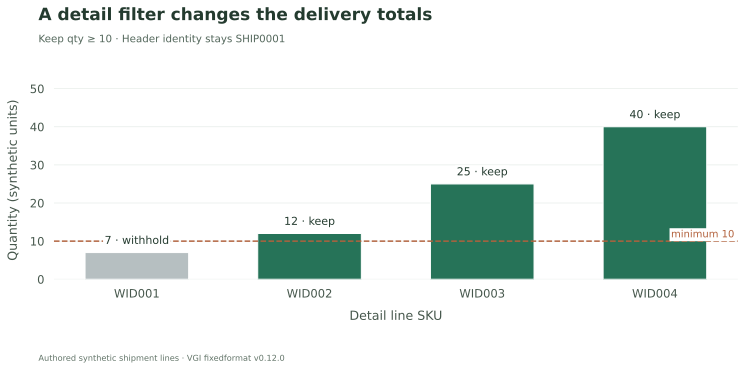

The selection keeps **3 of 4 detail lines** and **77 of 84 units**. It withholds **1 line / 7 units**. The unchanged incoming trailer would still describe four lines and 84 units. Rebuilding it describes this derived export; it does not revise the original delivery.

In [15]:
fig, ax = plt.subplots(figsize=(10.8, 5.4))
colors = ["#267358" if selected else "#B6BFC1" for selected in selected_lines.selected]
bars = ax.bar(selected_lines.sku, selected_lines.qty, color=colors, width=0.6)
ax.bar_label(
    bars,
    labels=[
        f"{q} · {'keep' if keep else 'withhold'}"
        for q, keep in zip(selected_lines.qty, selected_lines.selected)
    ],
    padding=6,
    fontsize=11,
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
)
ax.axhline(MIN_QTY, color="#B2613C", linewidth=1.5, linestyle="--")
ax.text(
    3.46,
    MIN_QTY + 1,
    f"minimum {MIN_QTY}",
    ha="right",
    color="#B2613C",
    fontsize=10,
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
)
ax.set_ylim(0, 52)
ax.set_ylabel("Quantity (synthetic units)")
ax.set_xlabel("Detail line SKU")
ax.grid(axis="y")
ax.set_axisbelow(True)
finish(
    fig,
    "A detail filter changes the delivery totals",
    f"Keep qty ≥ {MIN_QTY} · Header identity stays SHIP0001",
    "Authored synthetic shipment lines · VGI fixedformat v0.12.0",
    name=f"shipment-selection-{MIN_QTY}",
)
s = envelope.iloc[0]
prose(
    f"The selection keeps **{int(s.selected_lines)} of {len(selected_lines)} detail lines** "
    f"and **{int(s.selected_units)} of {int(selected_lines.qty.sum())} units**. "
    f"It withholds **{int(s.withheld_lines)} {'line' if int(s.withheld_lines) == 1 else 'lines'} / "
    f"{int(s.withheld_units)} units**. "
    "The unchanged incoming trailer would still describe four lines and 84 units. "
    "Rebuilding it describes this derived export; it does not revise the original delivery."
)

### Write two local products and read them back

`write_multi` takes the ordered UNION column, stamps its discriminator bytes and
writes header, retained details and rebuilt trailer. `write_fixed` takes just the
selected detail fields and writes a homogeneous extract for a consumer that does
not accept envelopes. That flat extract intentionally omits batch identity and trailer
controls; retain provenance separately if it is used outside this example.

Both write calls are materialized exactly once before displaying their summaries.
The reported byte counts include newline separators. Reads validate the actual files,
not only the in-memory inputs passed to the writers.


In [16]:
%%sql
CREATE TABLE mixed_write AS
 SELECT * FROM fixed.main.write_multi((SELECT record FROM outgoing ORDER BY sequence),
  '{{ mixed_sql }}',shipment_layout(),encoding=>'ascii',framing=>'newline',compression=>'none');
CREATE TABLE flat_write AS
 SELECT * FROM fixed.main.write_fixed((SELECT sku,qty FROM selected_details WHERE selected ORDER BY line_number),
  '{{ flat_sql }}','sku:A6 qty:9(5)',encoding=>'ascii',framing=>'newline');
CREATE TABLE mixed_readback AS
 SELECT row_number() OVER () AS sequence,record
 FROM fixed.main.read_multi('{{ mixed_sql }}',shipment_layout(),
                           encoding=>'ascii',framing=>'newline',compression=>'none');
CREATE TABLE flat_readback AS
 SELECT * FROM fixed.main.read_fixed('{{ flat_sql }}','sku:A6 qty:9(5)',
                                    encoding=>'ascii',framing=>'newline',compression=>'none');
SELECT 'mixed envelope' AS product,rows_written,bytes_written FROM mixed_write
 UNION ALL SELECT 'flat details',rows_written,bytes_written FROM flat_write;
SELECT * FROM flat_readback ORDER BY sku;
SELECT union_extract(record,'T').line_count AS declared_lines,
       union_extract(record,'T').total_units AS declared_units
 FROM mixed_readback WHERE union_tag(record)='T';


,declared_lines,declared_units
0,3,77


In [17]:
%%sql write_summary <<
SELECT 'mixed envelope' AS product,rows_written,bytes_written FROM mixed_write
UNION ALL SELECT 'flat details',rows_written,bytes_written FROM flat_write;


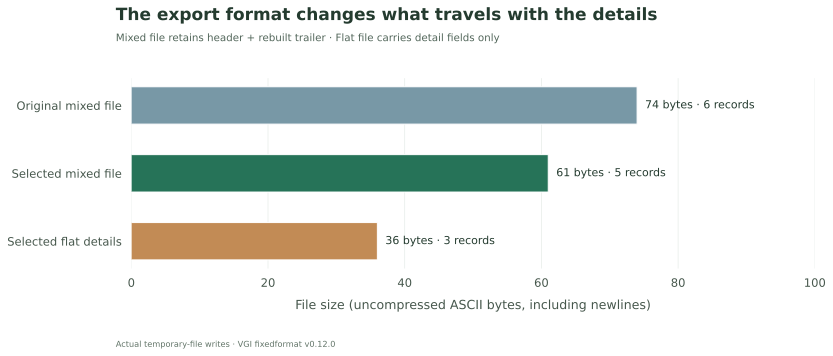

The corrected mixed file writes **5 records / 61 bytes**; the flat detail extract writes **3 records / 36 bytes**. Both readbacks retain the selected SKU quantities. The smaller flat file has a different contract: its size reduction includes removing the discriminator, header and trailer, not a compression improvement.

In [18]:
written = write_summary.set_index("product")
records = [
    len(raw_rows),
    int(written.loc["mixed envelope", "rows_written"]),
    int(written.loc["flat details", "rows_written"]),
]
byte_counts = [
    input_path.stat().st_size,
    int(written.loc["mixed envelope", "bytes_written"]),
    int(written.loc["flat details", "bytes_written"]),
]
fig, ax = plt.subplots(figsize=(10.8, 5.2))
bars = ax.barh(
    ["Original mixed file", "Selected mixed file", "Selected flat details"],
    byte_counts,
    color=["#7898A6", "#267358", "#C28B55"],
    height=0.55,
)
ax.bar_label(
    bars,
    labels=[f"{b} bytes · {r} records" for b, r in zip(byte_counts, records)],
    padding=8,
    fontsize=11,
)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("File size (uncompressed ASCII bytes, including newlines)")
ax.grid(axis="x")
ax.set_axisbelow(True)
finish(
    fig,
    "The export format changes what travels with the details",
    "Mixed file retains header + rebuilt trailer · Flat file carries detail fields only",
    "Actual temporary-file writes · VGI fixedformat v0.12.0",
    name=f"shipment-bytes-{MIN_QTY}",
)
prose(
    f"The corrected mixed file writes **{records[1]} records / {byte_counts[1]} bytes**; "
    f"the flat detail extract writes **{records[2]} records / {byte_counts[2]} bytes**. "
    "Both readbacks retain the selected SKU quantities. The smaller flat file has a different "
    "contract: its size reduction includes removing the discriminator, header and trailer, "
    "not a compression improvement."
)

### Check sequence, values and the envelope separately

The invariants include incoming controls, scalar/file agreement, inactive-variant
NULLs, selected/withheld conservation, output order, rebuilt controls, flat rows and
physical byte counts. A valid zero quantity would remain zero. These checks validate
this explicit ASCII/newline contract; they do not cover EBCDIC, binary framing,
compression, remote storage or arbitrary copybooks.


In [19]:
%%sql checks <<
SELECT 'Exactly one header first and one trailer last' AS invariant,
 (SELECT count(*) FILTER(WHERE union_tag(record)='H')=1 AND
         count(*) FILTER(WHERE union_tag(record)='T')=1 AND
         first(union_tag(record) ORDER BY line_number)='H' AND
         last(union_tag(record) ORDER BY line_number)='T' FROM incoming) AS passed
UNION ALL SELECT 'Incoming trailer agrees with detail count and units',
 (SELECT declared_lines=(SELECT count(*) FROM incoming_details) AND
         declared_units=(SELECT sum(qty) FROM incoming_details) FROM incoming_control)
UNION ALL SELECT 'Scalar and file decoding agree with multiplicity and order',
 NOT EXISTS ((SELECT * FROM incoming EXCEPT ALL SELECT * FROM scalar_records)
 UNION ALL (SELECT * FROM scalar_records EXCEPT ALL SELECT * FROM incoming))
UNION ALL SELECT 'Inactive detail variants are NULL, not zero',
 NOT EXISTS(SELECT 1 FROM incoming WHERE union_tag(record)!='D' AND union_extract(record,'D') IS NOT NULL)
UNION ALL SELECT 'Each synthetic detail SKU is unique',
 (SELECT count(*)=count(DISTINCT sku) FROM incoming_details)
UNION ALL SELECT 'Selected plus withheld conserve input lines and units',
 (SELECT selected_lines+withheld_lines=(SELECT count(*) FROM incoming_details) AND
         selected_units+withheld_units=(SELECT sum(qty) FROM incoming_details) FROM selection_totals)
UNION ALL SELECT 'Selected lines obey the inclusive threshold',
 NOT EXISTS(SELECT 1 FROM selected_details WHERE selected IS DISTINCT FROM (qty >= {{ MIN_QTY }}))
UNION ALL SELECT 'Mixed writer reports header + selected details + trailer',
 (SELECT rows_written=selected_lines+2 FROM mixed_write CROSS JOIN selection_totals)
UNION ALL SELECT 'Mixed readback preserves every selected union value in order',
 NOT EXISTS ((SELECT row_number() OVER(ORDER BY sequence) AS sequence,record FROM outgoing
              EXCEPT ALL SELECT * FROM mixed_readback)
 UNION ALL (SELECT * FROM mixed_readback EXCEPT ALL
            SELECT row_number() OVER(ORDER BY sequence) AS sequence,record FROM outgoing))
UNION ALL SELECT 'Rebuilt trailer agrees with actual exported details',
 (SELECT union_extract(record,'T').line_count=(SELECT count(*) FROM mixed_readback WHERE union_tag(record)='D') AND
         union_extract(record,'T').total_units=(SELECT sum(union_extract(record,'D').qty) FROM mixed_readback WHERE union_tag(record)='D')
 FROM mixed_readback WHERE union_tag(record)='T')
UNION ALL SELECT 'Flat readback preserves selected detail rows including multiplicity',
 NOT EXISTS ((SELECT sku,qty FROM selected_details WHERE selected EXCEPT ALL SELECT * FROM flat_readback)
 UNION ALL (SELECT * FROM flat_readback EXCEPT ALL SELECT sku,qty FROM selected_details WHERE selected))
UNION ALL SELECT 'Byte accounting matches layouts plus newline separators',
 (SELECT m.bytes_written=10+12+13*s.selected_lines AND f.bytes_written=12*s.selected_lines AND
         f.rows_written=s.selected_lines FROM mixed_write m CROSS JOIN flat_write f CROSS JOIN selection_totals s);


In [20]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
assert mixed_path.stat().st_size == int(written.loc["mixed envelope", "bytes_written"])
assert flat_path.stat().st_size == int(written.loc["flat details", "bytes_written"])
prose(
    f"**{len(checks)} SQL invariants and two actual-file byte checks passed.** "
    "The exported envelope is internally consistent with its selected detail population. "
    "This verifies the specified transformation, not the truth of the source shipment."
)

,invariant,passed
0,Exactly one header first and one trailer last,True
1,Incoming trailer agrees with detail count and ...,True
2,Scalar and file decoding agree with multiplici...,True
3,"Inactive detail variants are NULL, not zero",True
4,Each synthetic detail SKU is unique,True
5,Selected plus withheld conserve input lines an...,True
6,Selected lines obey the inclusive threshold,True
7,Mixed writer reports header + selected details...,True
8,Mixed readback preserves every selected union ...,True
9,Rebuilt trailer agrees with actual exported de...,True


**12 SQL invariants and two actual-file byte checks passed.** The exported envelope is internally consistent with its selected detail population. This verifies the specified transformation, not the truth of the source shipment.

### Experiment: raise the minimum from 10 to 20

Change only `MIN_QTY` to `20`, restart and run all. Predict the retained line count,
unit total, corrected trailer and both byte counts before inspecting the outputs.
The incoming envelope and variant layouts should remain unchanged. The twelve-unit
line joins the withheld population; the original trailer must still describe all
four original details. Reset `MIN_QTY=10` to restore the default export.

The accepted range is 0–40, ensuring this fixture retains at least one line. Designing
a zero-detail delivery requires an explicit business contract about whether an empty
envelope is valid; this notebook does not silently choose one.


In [21]:
session.close()
files.cleanup()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-fixedformat](https://github.com/Query-farm/vgi-fixedformat)
